# 02 - Feature engineering, model training & tracking
Runs the same code as `python -m src.train`.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))  # repo root (notebook lives in notebooks/)
import warnings; warnings.filterwarnings('ignore')
import pandas as pd
from IPython.display import Image, display
pd.set_option('display.max_columns', 30)

In [2]:
from src.data import load_clean_data, split_xy
from src.features import build_preprocessor
df = load_clean_data()
X, y = split_xy(df)
prep = build_preprocessor().fit(X)
print('features after preprocessing:', len(prep.get_feature_names_out()))
list(prep.get_feature_names_out())

features after preprocessing: 25


['num__age',
 'num__trestbps',
 'num__chol',
 'num__thalach',
 'num__oldpeak',
 'num__ca',
 'cat__sex_0',
 'cat__sex_1',
 'cat__cp_1',
 'cat__cp_2',
 'cat__cp_3',
 'cat__cp_4',
 'cat__fbs_0',
 'cat__fbs_1',
 'cat__restecg_0',
 'cat__restecg_1',
 'cat__restecg_2',
 'cat__exang_0',
 'cat__exang_1',
 'cat__slope_1',
 'cat__slope_2',
 'cat__slope_3',
 'cat__thal_3',
 'cat__thal_6',
 'cat__thal_7']

In [3]:
from src.train import run_training
result = run_training(df, use_mlflow=True, quick=True)   # set quick=False for the full grid
result['summary'][['model','cv_accuracy','cv_precision','cv_recall','cv_roc_auc','test_accuracy','test_roc_auc']].round(4)

,model,cv_accuracy,cv_precision,cv_recall,cv_roc_auc,test_accuracy,test_roc_auc
0,logistic_regression,0.8511,0.8776,0.7921,0.9113,0.8852,0.9610
1,random_forest,0.8179,0.8125,0.7917,0.8998,0.8689,0.9448
2,gradient_boosting,0.8304,0.8476,0.7830,0.8816,0.8852,0.9535


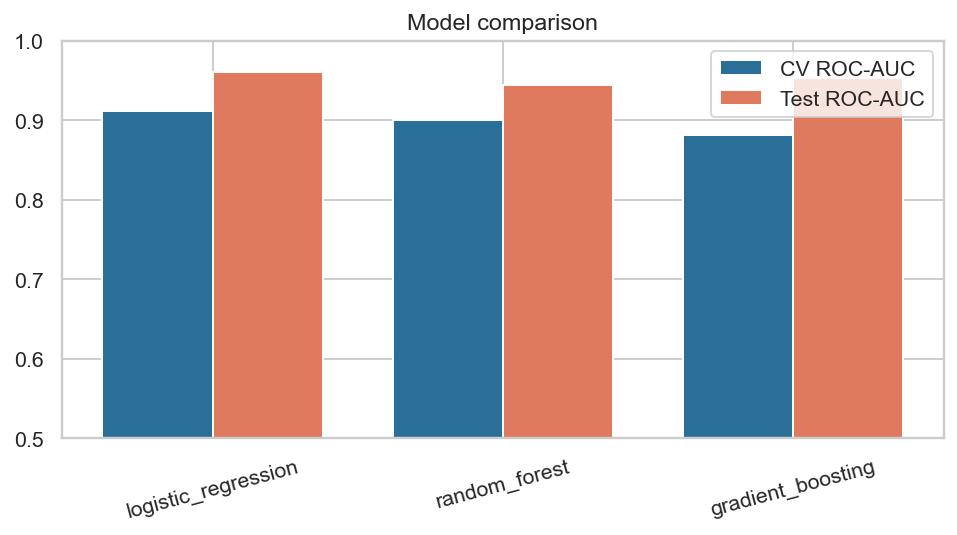

Selected: logistic_regression


{'model_name': 'logistic_regression',
 'model_version': '20261011054651',
 'trained_at': '2026-10-11T05:46:51.803381+00:00',
 'sklearn_version': '1.5.2',
 'features': ['age',
  'trestbps',
  'chol',
  'thalach',
  'oldpeak',
  'ca',
  'sex',
  'cp',
  'fbs',
  'restecg',
  'exang',
  'slope',
  'thal'],
 'target': 'target',
 'best_params': {'C': 0.1, 'class_weight': None},
 'cv_metrics': {'accuracy': 0.8511,
  'precision': 0.8776,
  'recall': 0.7921,
  'f1': 0.8299,
  'roc_auc': 0.9113},
 'test_metrics': {'accuracy': 0.8852,
  'precision': 0.8387,
  'recall': 0.9286,
  'f1': 0.8814,
  'roc_auc': 0.961},
 'n_train': 242,
 'data_file': 'heart_disease_clean.csv',
 'mlflow_run_id': '1b597b8b2f8b4a0faf7bf4305edd4a31'}

In [4]:
display(Image(filename='../reports/figures/model_comparison.png'))
print('Selected:', result['best_name'])
result['metadata']